In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('../Data/vendas-combustiveis-m3-1990-2025.csv', sep=';', decimal=';')

df.head()

c:\Users\Pichau\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
c:\Users\Pichau\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


,ANO,MÊS,GRANDE REGIÃO,UNIDADE DA FEDERAÇÃO,PRODUTO,VENDAS
0,1990,JAN,REGIÃO NORDESTE,MARANHÃO,ETANOL HIDRATADO,"7578,939"
1,1990,JUL,REGIÃO CENTRO-OESTE,GOIÁS,ETANOL HIDRATADO,"24462,251"
2,1990,JUN,REGIÃO CENTRO-OESTE,GOIÁS,ETANOL HIDRATADO,"25005,954"
3,1990,MAI,REGIÃO CENTRO-OESTE,GOIÁS,ETANOL HIDRATADO,"18888,239"
4,1990,ABR,REGIÃO CENTRO-OESTE,GOIÁS,ETANOL HIDRATADO,"27535,918"


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 94608 entries, 0 to 94607
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   ANO                   94608 non-null  int64
 1   MÊS                   94608 non-null  str  
 2   GRANDE REGIÃO         94608 non-null  str  
 3   UNIDADE DA FEDERAÇÃO  94608 non-null  str  
 4   PRODUTO               94608 non-null  str  
 5   VENDAS                94608 non-null  str  
dtypes: int64(1), str(5)
memory usage: 8.9 MB


In [3]:
df['VENDAS'] = (
    df['VENDAS']
    .str.replace(',', '.', regex=False)
    .astype(float)
)

In [4]:
vendas_produto = (
    df[df['ANO'].between(1990, 2025)]
    .groupby('PRODUTO')['VENDAS']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

pd.options.display.float_format = '{:,.2f}'.format
vendas_produto

,PRODUTO,VENDAS
0,ÓLEO DIESEL,"1,627,401,439.83"
1,GASOLINA C,"1,056,854,877.04"
2,GLP,"438,366,683.08"
3,ETANOL HIDRATADO,"419,790,342.03"
4,ÓLEO COMBUSTÍVEL,"213,922,656.29"
5,QUEROSENE DE AVIAÇÃO,"188,777,491.54"
6,QUEROSENE ILUMINANTE,"3,140,457.17"
7,GASOLINA DE AVIAÇÃO,"2,216,595.36"


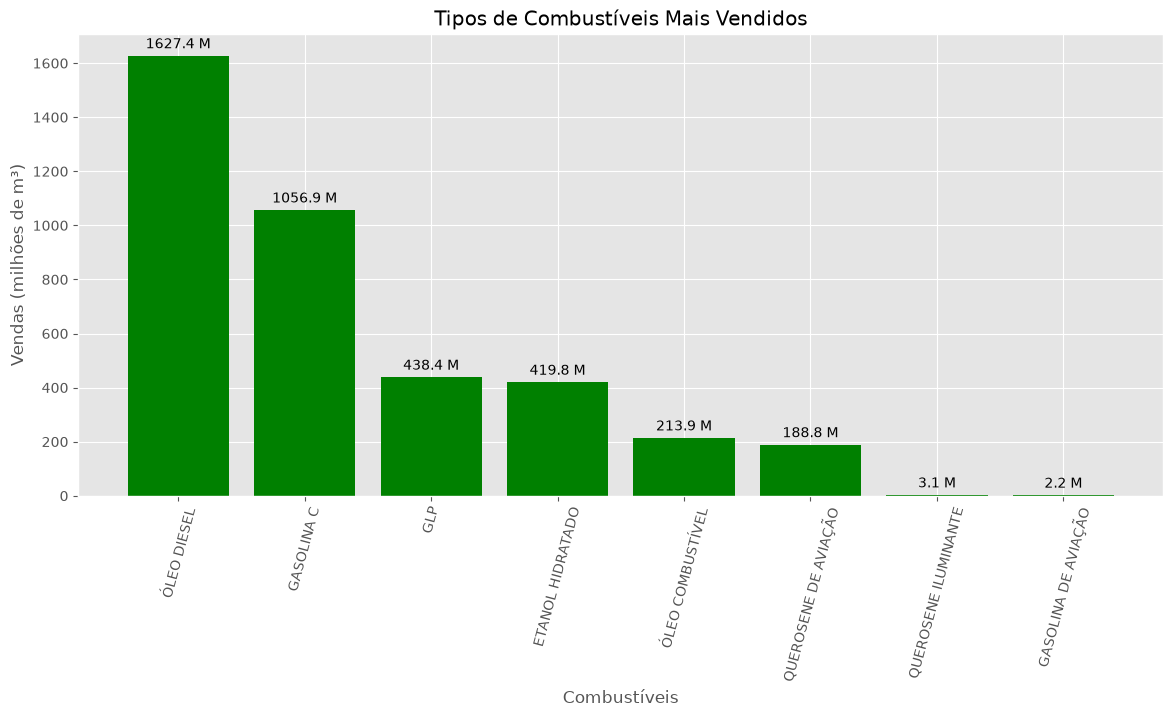

In [28]:
plt.figure(figsize=(14, 6))

plt.style.use('ggplot')

barras = plt.bar(
    vendas_produto['PRODUTO'],
    vendas_produto['VENDAS'] / 1e6,
    color='green'
)

plt.title('Tipos de Combustíveis Mais Vendidos')
plt.xlabel('Combustíveis')
plt.ylabel('Vendas (milhões de m³)')

plt.tick_params(axis='x', rotation=75)

plt.bar_label(barras, fmt='%.1f M', padding=3);

In [6]:
vendas_ano = (
    df[df['ANO'].between(1990, 2025)]
    .groupby('ANO')['VENDAS']
    .sum()
    .reset_index()
)

vendas_ano

,ANO,VENDAS
0,1990,"72,997,178.79"
1,1991,"70,049,243.82"
2,1992,"68,758,843.51"
3,1993,"71,351,348.68"
4,1994,"74,558,939.49"
5,1995,"79,881,993.14"
6,1996,"86,716,992.94"
7,1997,"88,885,824.28"
8,1998,"92,007,593.52"
9,1999,"92,054,878.86"


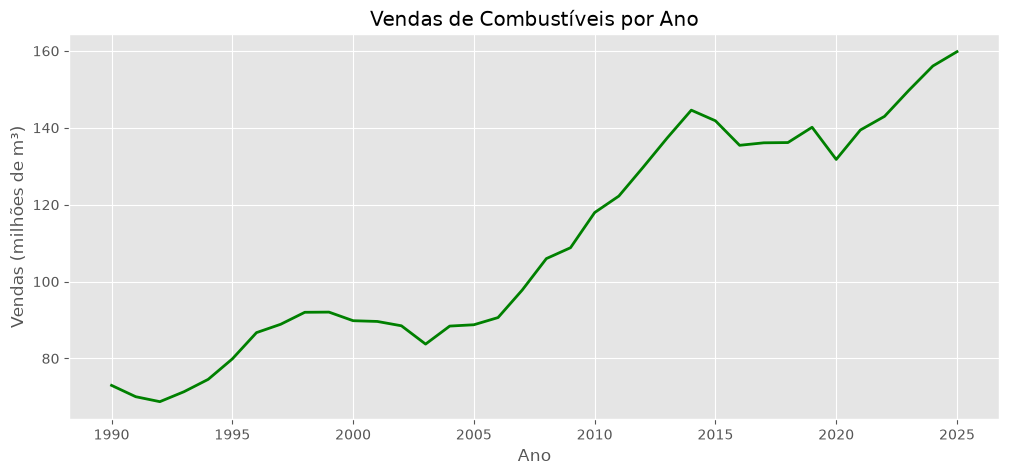

In [7]:
plt.figure(figsize=(12, 5))

plt.style.use('ggplot')

plt.plot(
    vendas_ano['ANO'],
    vendas_ano['VENDAS'] / 1e6,
    linewidth=2,
    color='green'
)

plt.title('Vendas de Combustíveis por Ano')
plt.xlabel('Ano')
plt.ylabel('Vendas (milhões de m³)');

In [8]:
vendas_uf = (
    df[df['ANO'].between(1990, 2025)]
    .groupby('UNIDADE DA FEDERAÇÃO')['VENDAS']
    .sum()
    .sort_values(ascending=False)
    .nlargest(10)
    .reset_index()
)

vendas_uf

,UNIDADE DA FEDERAÇÃO,VENDAS
0,SÃO PAULO,"1,117,489,854.53"
1,MINAS GERAIS,"435,875,129.61"
2,PARANÁ,"298,164,021.98"
3,RIO DE JANEIRO,"252,682,101.87"
4,RIO GRANDE DO SUL,"246,256,946.27"
5,BAHIA,"202,185,025.29"
6,SANTA CATARINA,"168,695,426.47"
7,GOIÁS,"164,002,639.07"
8,PARÁ,"123,076,469.34"
9,MATO GROSSO,"117,138,535.75"


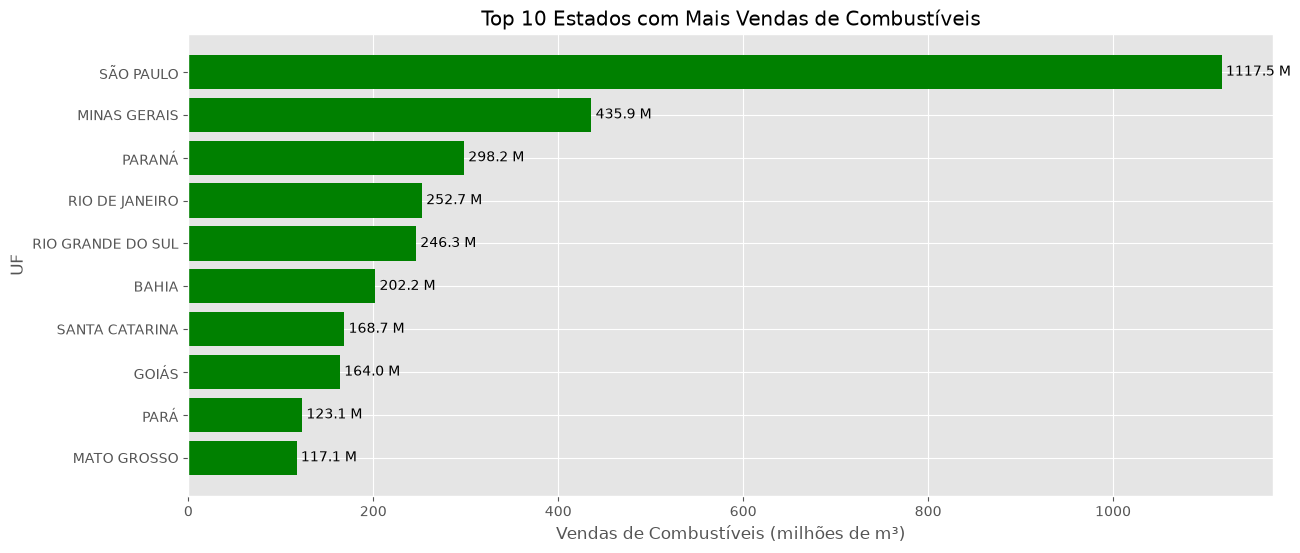

In [9]:
plt.figure(figsize=(14, 6))

barras = plt.barh(
    vendas_uf['UNIDADE DA FEDERAÇÃO'],
    vendas_uf['VENDAS'] / 1e6,
    color='green'
)

plt.title('Top 10 Estados com Mais Vendas de Combustíveis')
plt.xlabel('Vendas de Combustíveis (milhões de m³)')
plt.ylabel('UF')

plt.gca().invert_yaxis()

plt.bar_label(barras, fmt='%.1f M', padding=3);

In [10]:
df_segmento = pd.read_csv('../Data/vendas-combustiveis-segmento-m3-2012-2025.csv', sep=';')

df_segmento.head()

,ANO,MÊS,UNIDADE DA FEDERAÇÃO,PRODUTO,SEGMENTO,VENDAS
0,2012,JAN,RONDÔNIA,ETANOL HIDRATADO,POSTO REVENDEDOR,"1560,5"
1,2012,MAI,DISTRITO FEDERAL,ETANOL HIDRATADO,CONSUMIDOR FINAL,50
2,2012,JUN,DISTRITO FEDERAL,ETANOL HIDRATADO,CONSUMIDOR FINAL,25
3,2012,JUL,DISTRITO FEDERAL,ETANOL HIDRATADO,CONSUMIDOR FINAL,25
4,2012,AGO,DISTRITO FEDERAL,ETANOL HIDRATADO,CONSUMIDOR FINAL,20


In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 94608 entries, 0 to 94607
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   ANO                   94608 non-null  int64  
 1   MÊS                   94608 non-null  str    
 2   GRANDE REGIÃO         94608 non-null  str    
 3   UNIDADE DA FEDERAÇÃO  94608 non-null  str    
 4   PRODUTO               94608 non-null  str    
 5   VENDAS                94608 non-null  float64
dtypes: float64(1), int64(1), str(4)
memory usage: 8.2 MB


In [12]:
df_segmento['VENDAS'] = (
    df_segmento['VENDAS']
    .str.replace(',', '.', regex=False)
    .astype(float)
)

In [13]:
vendas_segmento = (
    df_segmento.groupby('SEGMENTO')['VENDAS']
    .sum()
    .round(2)
    .sort_values(ascending=False)
    .reset_index()
)

vendas_segmento

,SEGMENTO,VENDAS
0,POSTO REVENDEDOR,"1,355,498,492.98"
1,CONSUMIDOR FINAL,"241,202,077.56"
2,TRR,"128,937,046.55"


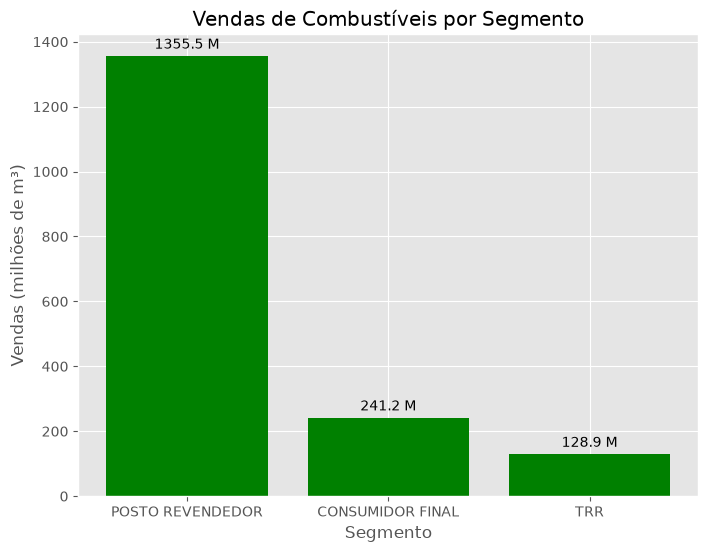

In [14]:
plt.figure(figsize=(8, 6))

barras = plt.bar(
    vendas_segmento['SEGMENTO'],
    vendas_segmento['VENDAS'] / 1e6,
    color='green'
)

plt.title('Vendas de Combustíveis por Segmento')
plt.xlabel('Segmento')
plt.ylabel('Vendas (milhões de m³)')

plt.bar_label(barras, fmt='%.1f M', padding=3);

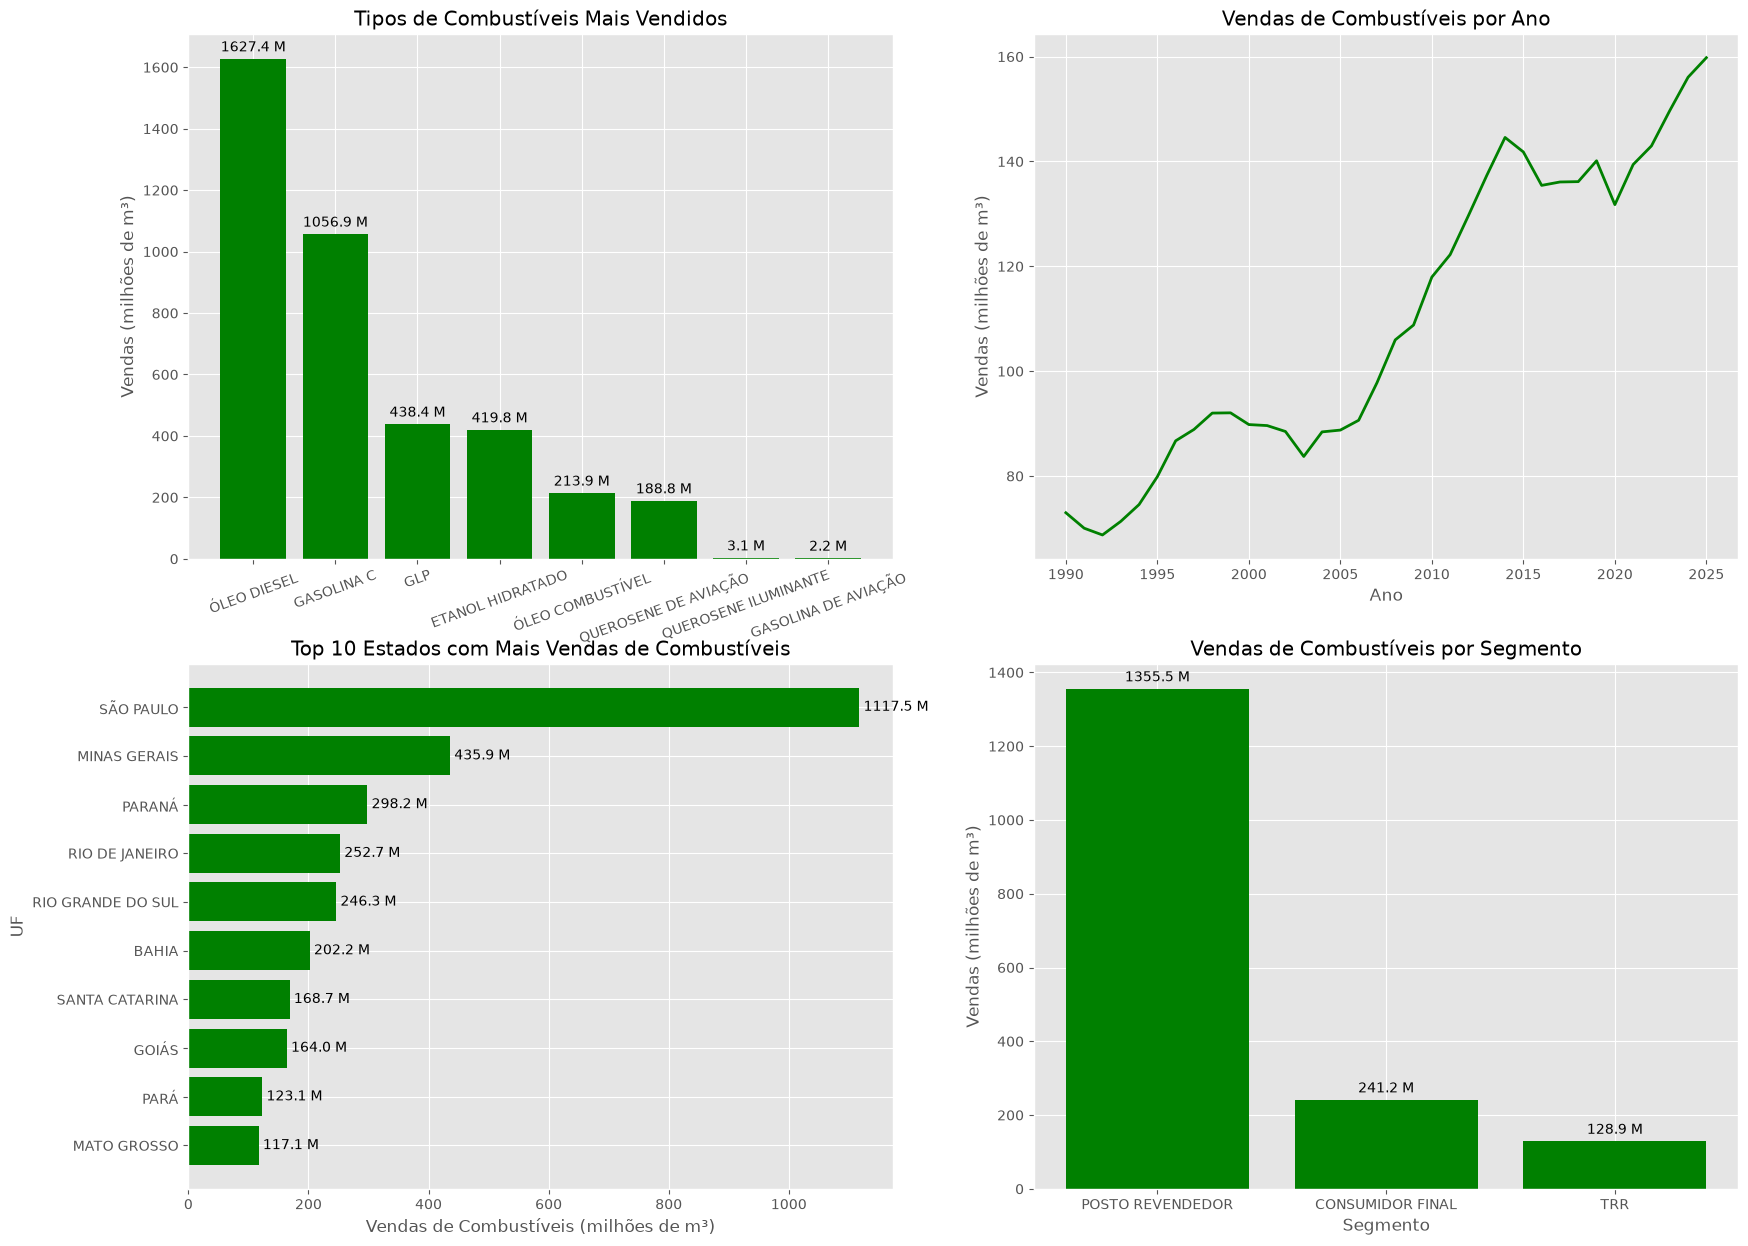

In [34]:
fig, ax = plt.subplots(2, 2, figsize=(20, 15))

plt.style.use('ggplot')

barras = ax[0, 0].bar(
    vendas_produto['PRODUTO'],
    vendas_produto['VENDAS'] / 1e6,
    color='green'
)

ax[0, 0].set_title('Tipos de Combustíveis Mais Vendidos')
ax[0, 0].set_ylabel('Vendas (milhões de m³)')
ax[0, 0].tick_params(axis='x', rotation=20)
ax[0, 0].bar_label(barras, fmt='%.1f M', padding=3)

ax[0, 1].plot(
    vendas_ano['ANO'],
    vendas_ano['VENDAS'] / 1e6,
    linewidth=2,
    color='green'
)

ax[0, 1].set_title('Vendas de Combustíveis por Ano')
ax[0, 1].set_xlabel('Ano')
ax[0, 1].set_ylabel('Vendas (milhões de m³)')

barras = ax[1, 0].barh(
    vendas_uf['UNIDADE DA FEDERAÇÃO'],
    vendas_uf['VENDAS'] / 1e6,
    color='green'
)

ax[1, 0].set_title('Top 10 Estados com Mais Vendas de Combustíveis')
ax[1, 0].set_xlabel('Vendas de Combustíveis (milhões de m³)')
ax[1, 0].set_ylabel('UF')
ax[1, 0].invert_yaxis()
ax[1, 0].bar_label(barras, fmt='%.1f M', padding=3)

barras = ax[1, 1].bar(
    vendas_segmento['SEGMENTO'],
    vendas_segmento['VENDAS'] / 1e6,
    color='green'
)

ax[1, 1].set_title('Vendas de Combustíveis por Segmento')
ax[1, 1].set_xlabel('Segmento')
ax[1, 1].set_ylabel('Vendas (milhões de m³)')
ax[1, 1].bar_label(barras, fmt='%.1f M', padding=3);



In [15]:
df.to_csv(
    'vendas_combustiveis.csv',
    sep=';',
    decimal=',',
    index=False
)

df_segmento.to_csv(
    'vendas_combustiveis_segmento.csv',
    sep=';',
    decimal=',',
    index=False
)
